In [1]:
#%pip install torch matplotlib scipy
import torch
import matplotlib.pyplot as plt
from scipy.io import loadmat

In [2]:
def init_model(nx, nh, ny, eta):
    model = torch.nn.Sequential(
        torch.nn.Linear(nx, nh),
        torch.nn.Tanh(),
        torch.nn.Linear(nh, ny),
    )
    # CrossEntropyLoss applies the softmax itself (the model outputs y_tilde)
    loss = torch.nn.CrossEntropyLoss()
    # the optimizer holds a reference to the parameters it updates
    optim = torch.optim.SGD(model.parameters(), lr=eta)
    return model, loss, optim

In [3]:
def loss_accuracy(loss, y_tilde, y):
    # CrossEntropyLoss expects class indices, not one-hot vectors
    _, indsY = torch.max(y, 1)
    L = loss(y_tilde, indsY)

    # argmax of y_tilde == argmax of softmax(y_tilde) because no softmax needed here
    _, indsYhat = torch.max(y_tilde, 1)
    acc = torch.mean((indsY == indsYhat).float())

    return L, acc

epoch   0 | train loss 0.2771 acc 0.921 | test loss 0.2704 acc 0.924
epoch   1 | train loss 0.2147 acc 0.939 | test loss 0.2138 acc 0.937
epoch   2 | train loss 0.1795 acc 0.949 | test loss 0.1840 acc 0.947
epoch   3 | train loss 0.1505 acc 0.957 | test loss 0.1597 acc 0.953
epoch   4 | train loss 0.1307 acc 0.963 | test loss 0.1409 acc 0.959
epoch   5 | train loss 0.1136 acc 0.968 | test loss 0.1260 acc 0.964
epoch   6 | train loss 0.0995 acc 0.973 | test loss 0.1160 acc 0.965
epoch   7 | train loss 0.0894 acc 0.975 | test loss 0.1051 acc 0.969
epoch   8 | train loss 0.0807 acc 0.978 | test loss 0.1001 acc 0.969
epoch   9 | train loss 0.0752 acc 0.980 | test loss 0.0984 acc 0.971
epoch  10 | train loss 0.0678 acc 0.982 | test loss 0.0906 acc 0.972
epoch  11 | train loss 0.0633 acc 0.983 | test loss 0.0881 acc 0.973
epoch  12 | train loss 0.0590 acc 0.984 | test loss 0.0842 acc 0.974
epoch  13 | train loss 0.0559 acc 0.985 | test loss 0.0834 acc 0.974
epoch  14 | train loss 0.0500 acc 

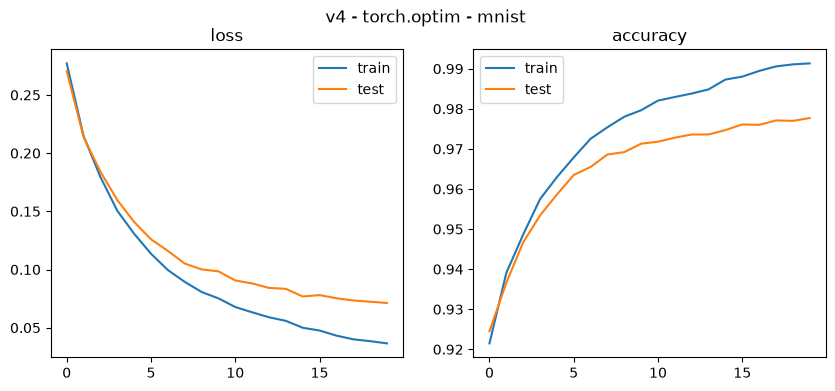

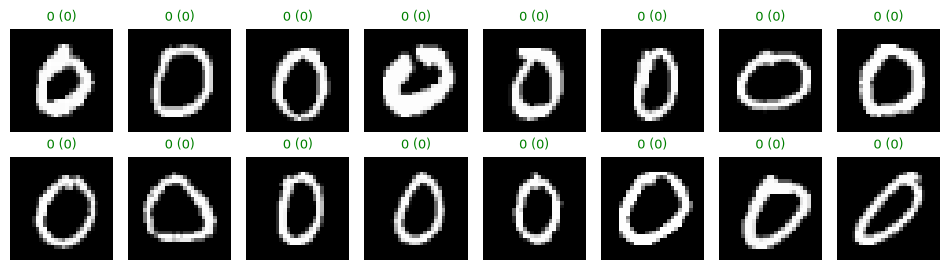

In [4]:
import utils
utils.set_seed(42)

data = utils.load_data("mnist")
nh, Nbatch, eta, Nepoch = 100, 64, 0.1, 20

model, loss, optim = init_model(data[0].shape[1], nh, data[1].shape[1], eta)

def step(Xb, yb):
    y_tilde = model(Xb)
    L, _ = loss_accuracy(loss, y_tilde, yb)
    optim.zero_grad()  # reset gradients before computing the new ones
    L.backward()
    optim.step()  # param -= eta * param.grad for every parameter

def predict(X):
    # utils.py expects probabilities (softmax required)
    return torch.softmax(model(X), dim=1)

curves = utils.train(step, predict, data, Nbatch, Nepoch)
utils.plot_curves(curves, "v4 - torch.optim - mnist")
utils.show_mnist(data[2], data[3], predict)